# Actual Clifford+T replay of one supported QAOA trajectory

This notebook audits saved compilation and conditional resource records for the four-wire C4 QAOA depth-two run with alternate start and seed `7`. It is the first holdout-supported run in the frozen recipe order. The selected classical decisions, angle values, rejected proposals, shot allocations and final holdout are immutable inputs to this replay. Fresh measurements, synthesis error or hardware noise are not allowed to drive a new optimizer path in this cost calculation.

**Audit status:** completed saved compilation and lossless physical-recovery artifacts are required before this notebook can execute. The notebook performs saved-record checks only: it does not optimize angles, draw new samples, synthesize rotations or query a physical estimator. Actual Clifford+T sequences, logical line routing, explicit input resets, all repeated preparations and joint all-Z readout must be inspectable in the saved circuit bundle.

The conditional surface-code scenario includes specified initialization, readout, routing/injection, feedback and capped factory-supply assumptions. Numerical synthesis guards and tiny ideal checks are evidence rather than formal interval certificates or hardware calibration. No convergence, unchanged adaptive-path, quantum-advantage or hardware-success guarantee follows. **Classical C4 reference coverage only.** The earlier VQE ideal hits keep their original inconclusive holdout labels.

The saved original physical attempt failed at the representation boundary. One declared computation-only recovery preserved all 54 synthesized checkpoints and used a lossless shared JSON-DAG representation. Both native-query counts and CPU times remain charged; source preparations and T states are counted once. Complete first-pass point records were unavailable, so no equality to that missing result is claimed. This public audit requires no private pickle.


In [1]:
from pathlib import Path
from collections import Counter
from fractions import Fraction
import hashlib
import importlib.metadata
import json
import math
import platform
import sys
sys.dont_write_bytecode = True

import numpy as np
from qiskit import qasm3

cwd = Path.cwd().resolve()
folders = (cwd / 'assets/generated/optimization/compiled-replay',
           cwd.parent / 'assets/generated/optimization/compiled-replay', cwd)
artifact_folder = next((path.resolve() for path in folders
                        if (path / 'manifest.json').is_file()), None)
if artifact_folder is None:
    raise FileNotFoundError('Save the complete compiled-replay artifact directory beside this notebook, or run from the checkout. No compilation or estimation will be started by this audit.')

def digest_bytes(raw):
    return hashlib.sha256(raw).hexdigest()

def read_json(name):
    if Path(name).is_absolute() or ".." in Path(name).parts:
        raise ValueError("Saved-record names must be relative without parent traversal")
    lexical = artifact_folder / name
    if any(item.is_symlink() for item in [lexical, *lexical.parents] if item.is_relative_to(artifact_folder)):
        raise ValueError("Saved-record paths must not traverse symbolic links")
    path = lexical.resolve()
    if not path.is_relative_to(artifact_folder) or not path.is_file():
        raise ValueError('Saved-record paths must be ordinary files inside the artifact bundle')
    return json.loads(path.read_text()), digest_bytes(path.read_bytes())

manifest, manifest_sha256 = read_json('manifest.json')
if manifest.get('artifact_status', manifest.get('status')) != 'complete':
    raise ValueError('This audit requires the complete compilation/resource bundle; incomplete records are retained without being called validated')
recipe, recipe_sha256 = read_json('recipe.json')
transcript, transcript_sha256 = read_json('selected-transcript.json')
print({'mode': 'saved-record audit only', 'manifest_sha256': manifest_sha256,
       'recipe_sha256': recipe_sha256, 'selected_transcript_sha256': transcript_sha256,
       'python': platform.python_version(),
       'packages': {name: importlib.metadata.version(name) for name in ('qiskit', 'numpy', 'qdk')}})


{'mode': 'saved-record audit only', 'manifest_sha256': 'a4e0bbd7e1063713bd4faa5af82ce2bed0a3c10201f99cbf0d53b61c507d34eb', 'recipe_sha256': '6f421cfef08d7b552433a9360ce5091f5fb4c8dc21f4ba0b14143da4f6ddd343', 'selected_transcript_sha256': '4a988dcc5651c15d994a256f01982a536227ba92549bf1e08cad4c3549b529ef', 'python': '3.12.14', 'packages': {'qiskit': '2.6.2', 'numpy': '2.5.4', 'qdk': '1.34.0'}}


## Independent count and decision checks

The original sampler scored all cut edges jointly. Recomputing the mean and sample variance from each integer bitstring count retains within-shot covariance. The decision replay uses those sampled values and errors, not an exact expectation. All proposals follow the fixed coordinate order and periodic angle domain; equality with the descriptive margin is rejected.


In [2]:
WIDTH = 4
EDGES = ((0, 1), (1, 2), (2, 3), (0, 3))
INDICES = np.arange(1 << WIDTH)
CUTS = np.array([sum(((z >> u) ^ (z >> v)) & 1 for u, v in EDGES)
                 for z in INDICES], dtype=float)
assert int(CUTS.max()) == 4

def count_moments(group):
    shots, counts = group['shots'], group['counts']
    assert isinstance(shots, int) and not isinstance(shots, bool) and shots >= 2
    assert counts and sum(counts.values()) == shots
    assert all(isinstance(number, int) and not isinstance(number, bool) and number > 0
               and len(bits) == WIDTH and not (set(bits) - {'0', '1'})
               for bits, number in counts.items())
    mean = sum(number * CUTS[int(bits, 2)] for bits, number in counts.items()) / shots
    variance = sum(number * (CUTS[int(bits, 2)] - mean) ** 2
                   for bits, number in counts.items()) / (shots - 1)
    return mean, variance, math.sqrt(variance / shots)

def wrap(point):
    return (np.asarray(point, dtype=float) + np.pi) % (2 * np.pi) - np.pi

def replay_count_decisions(run):
    assert run['initial'] == [.6, .4, .6, .4]
    assert run['seed'] == 7 and run['stream_id'] == 33
    assert run['objective_evaluations'] == len(run['evaluations']) == 109
    assert len(run['iterations']) == 12 and run['convergence_certified'] is False
    point, current = wrap(run['initial']), run['evaluations'][0]
    calls, accepted_indexes, index = run['evaluations'], set(), 1
    allocations = [128] + [shots for shots in (260, 520, 1040) for _ in range(36)]
    assert [call['index'] for call in calls] == list(range(109))
    for call, shots in zip(calls, allocations):
        assert [group['group'] for group in call['groups']] == ['all_z']
        assert call['total_shots'] == shots == call['groups'][0]['shots']
        mean, variance, se = count_moments(call['groups'][0])
        np.testing.assert_allclose([call['objective_estimate'], call['estimated_standard_error'],
                                   call['groups'][0]['estimate'], call['groups'][0]['sample_variance']],
                                  [-mean, se, mean, variance], rtol=1e-12, atol=1e-12)
    assert current['role'] == 'initial' and not current['accepted']
    np.testing.assert_allclose(current['parameters'], point, rtol=0, atol=1e-14)
    for sweep, iteration in enumerate(run['iterations']):
        incumbent = calls[index]
        proposal_indexes = list(range(index + 1, index + 9))
        assert iteration['index'] == sweep
        assert iteration['step'] == (.4, .2, .1)[sweep // 4]
        assert iteration['shots_per_group'] == (260, 520, 1040)[sweep // 4]
        assert iteration['incumbent_evaluation'] == index
        assert iteration['proposal_evaluations'] == proposal_indexes
        assert incumbent['role'] == 'incumbent' and not incumbent['accepted']
        np.testing.assert_allclose(incumbent['parameters'], point, rtol=0, atol=1e-14)
        np.testing.assert_allclose(iteration['parameters_before'], point, rtol=0, atol=1e-14)
        proposals = [calls[number] for number in proposal_indexes]
        for offset, proposal in enumerate(proposals):
            axis, direction = offset // 2, -1 if offset % 2 == 0 else 1
            assert proposal['role'] == 'proposal'
            assert (proposal['axis'], proposal['direction']) == (axis, direction)
            trial = point.copy(); trial[axis] += direction * iteration['step']
            np.testing.assert_allclose(proposal['parameters'], wrap(trial), rtol=0, atol=1e-14)
        best = min(proposals, key=lambda call: call['objective_estimate'])
        margin = 2 * math.hypot(incumbent['estimated_standard_error'], best['estimated_standard_error'])
        improvement = incumbent['objective_estimate'] - best['objective_estimate']
        accepted = improvement > margin
        assert iteration['accepted'] == accepted
        assert iteration['best_proposal_evaluation'] == best['index']
        np.testing.assert_allclose([iteration['comparison_margin'], iteration['sampled_improvement']],
                                  [margin, improvement], rtol=1e-12, atol=1e-14)
        if accepted:
            accepted_indexes.add(best['index']); current = best; point = np.array(best['parameters'])
        else:
            current = incumbent
        np.testing.assert_allclose(iteration['parameters_after'], point, rtol=0, atol=1e-14)
        index += 9
    assert index == len(calls)
    assert {call['index'] for call in calls if call['accepted']} == accepted_indexes
    assert run['accepted_proposals'] == len(accepted_indexes)
    assert run['rejected_proposals'] == 96 - len(accepted_indexes)
    assert run['stop_reason'] == 'fixed_schedule_exhausted'
    np.testing.assert_allclose(run['parameters'], point, rtol=0, atol=1e-14)
    np.testing.assert_allclose([run['final_training_estimate'], run['final_training_standard_error']],
                              [current['objective_estimate'], current['estimated_standard_error']],
                              rtol=1e-12, atol=1e-14)
    return calls


## Independent four-wire circuit interpreter

The circuit audit separates initial reset, coherent work and terminal classical readout. Reset is a channel, not a unitary gate. The following NumPy interpreter uses explicit primitive matrices and bit permutations for the coherent suffix. It restores the separately recorded overall phase and uses the actual final qubit-to-classical map to compare classical distributions and unitary output rows. Checking only the cut mean would be insufficient: C4 symmetry can hide an incorrect wire permutation.


In [3]:
from functools import lru_cache

CLIFFORD_T = {'h', 'x', 'y', 'z', 's', 'sdg', 't', 'tdg', 'cx'}

@lru_cache(maxsize=128)
def primitive_matrix(name, angle=None):
    identity = np.eye(2, dtype=complex)
    x = np.array([[0, 1], [1, 0]], dtype=complex)
    y = np.array([[0, -1j], [1j, 0]], dtype=complex)
    z = np.diag([1., -1.]).astype(complex)
    fixed = {'h': np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2),
             'x': x, 'y': y, 'z': z,
             's': np.diag([1, 1j]), 'sdg': np.diag([1, -1j]),
             't': np.diag([1, np.exp(1j * np.pi / 4)]),
             'tdg': np.diag([1, np.exp(-1j * np.pi / 4)])}
    if name in fixed: return fixed[name]
    assert angle is not None and math.isfinite(angle)
    c, s = np.cos(angle / 2), np.sin(angle / 2)
    if name == 'rx': return c * identity - 1j * s * x
    if name == 'ry': return np.array([[c, -s], [s, c]], dtype=complex)
    if name == 'rz': return np.diag([np.exp(-1j * angle / 2), np.exp(1j * angle / 2)])
    raise ValueError(f'Unsupported primitive in independent interpreter: {name}')

def independent_qaoa_state(parameters):
    assert len(parameters) == 4
    state = np.ones(1 << WIDTH, dtype=complex) / np.sqrt(1 << WIDTH)
    for gamma, beta in zip(parameters[::2], parameters[1::2]):
        state *= np.exp(-1j * gamma * CUTS)
        for q in range(WIDTH):
            state = np.cos(beta) * state - 1j * np.sin(beta) * state[INDICES ^ (1 << q)]
    return state

def phase_aligned_error(actual, expected):
    overlap = np.vdot(expected, actual)
    phase = overlap / abs(overlap) if abs(overlap) else 1.
    return float(np.linalg.norm(actual - phase * expected)), phase


In [4]:
import ast
import re

def finite_angle_expression(text):
    tree = ast.parse(text, mode='eval')
    if sum(1 for _ in ast.walk(tree)) > 32:
        raise ValueError('Angle expression exceeds the restricted QASM audit domain')
    def scalar(node):
        if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
            return float(node.value)
        if isinstance(node, ast.Name) and node.id == 'pi': return math.pi
        if isinstance(node, ast.UnaryOp) and isinstance(node.op, (ast.UAdd, ast.USub)):
            value = scalar(node.operand)
            return value if isinstance(node.op, ast.UAdd) else -value
        if isinstance(node, ast.BinOp) and isinstance(node.op, (ast.Add, ast.Sub, ast.Mult, ast.Div)):
            a, b = scalar(node.left), scalar(node.right)
            if isinstance(node.op, ast.Add): return a + b
            if isinstance(node.op, ast.Sub): return a - b
            if isinstance(node.op, ast.Mult): return a * b
            return a / b
        raise ValueError('Unsupported QASM angle expression')
    value = scalar(tree.body)
    if not math.isfinite(value): raise ValueError('QASM angle is not finite')
    return value

def primitive_qasm_operations(text):
    # This is a strict audit of our exported primitive subset, not a general
    # QASM compiler. Unknown declarations, gates or control flow are rejected.
    quantum, classical, operations, physical_wires = {}, {}, [], set()
    def operand(text, registers):
        physical = re.fullmatch(r'\$(\d+)', text.strip())
        if physical:
            number = int(physical.group(1))
            if registers is not quantum or not 0 <= number < WIDTH:
                raise ValueError('Invalid known routed physical-wire marker')
            physical_wires.add(number)
            return number
        match = re.fullmatch(r'([A-Za-z_][A-Za-z_0-9]*)\[(\d+)\]', text.strip())
        if not match: raise ValueError('Nonliteral QASM bit operand')
        name, number = match.group(1), int(match.group(2))
        if name not in registers or not 0 <= number < registers[name][1]:
            raise ValueError('QASM bit is outside its declared register')
        return registers[name][0] + number
    for original in text.splitlines():
        line = original.strip()
        if not line or line.startswith('//'): continue
        if line in {'OPENQASM 3.0;', 'include "stdgates.inc";'}: continue
        match = re.fullmatch(r'(qubit|bit)\[(\d+)\] ([A-Za-z_][A-Za-z_0-9]*);', line)
        if match:
            registers = quantum if match.group(1) == 'qubit' else classical
            name, size = match.group(3), int(match.group(2))
            if name in registers: raise ValueError('Repeated QASM register')
            registers[name] = (sum(value[1] for value in registers.values()), size)
            continue
        match = re.fullmatch(r'(.+) = measure (.+);', line)
        if match:
            operations.append(['measure', [operand(match.group(2), quantum)],
                               [operand(match.group(1), classical)], []]); continue
        match = re.fullmatch(r'([a-z]+)(?:\(([^()]*)\))? (.+);', line)
        if not match: raise ValueError(f'Unsupported primitive QASM line: {line}')
        name, angle, wires_text = match.groups()
        if name not in CLIFFORD_T | {'rx', 'ry', 'rz', 'reset', 'barrier'}:
            raise ValueError(f'Unsupported primitive QASM operation: {name}')
        wires = [operand(token, quantum) for token in wires_text.split(',')]
        params = [finite_angle_expression(angle)] if name in {'rx', 'ry', 'rz'} else []
        if (angle is not None) != (name in {'rx', 'ry', 'rz'}):
            raise ValueError('Unexpected primitive QASM parameter')
        if name == 'cx' and len(wires) != 2: raise ValueError('Invalid QASM CX arity')
        if name not in {'cx', 'barrier'} and len(wires) != 1: raise ValueError('Invalid QASM primitive arity')
        operations.append([name, wires, [], params])
    if physical_wires:
        assert not quantum and physical_wires == set(range(WIDTH))
    else:
        assert sum(value[1] for value in quantum.values()) == WIDTH
    assert sum(value[1] for value in classical.values()) == WIDTH
    return operations

def coherent_operations_and_map(operations, saved_phase, *, require_resets=True):
    assert math.isfinite(saved_phase)
    operator = np.eye(1 << WIDTH, dtype=complex)
    initialized = set() if require_resets else set(range(WIDTH))
    measured, coherent_started, measure_started = [], False, False
    if not require_resets: assert not any(row[0] == 'reset' for row in operations)
    for name, wires, clbits, params in operations:
        if name == 'barrier': continue
        if name == 'reset':
            assert not coherent_started and not measure_started and len(wires) == 1
            assert wires[0] not in initialized and not clbits and not params
            initialized.add(wires[0]); continue
        if name == 'measure':
            assert coherent_started and initialized == set(range(WIDTH))
            assert len(wires) == len(clbits) == 1 and not params
            measure_started = True; measured.append((wires[0], clbits[0])); continue
        assert not measure_started and initialized == set(range(WIDTH)) and not clbits
        coherent_started = True
        if name == 'cx':
            assert len(wires) == 2 and wires[0] != wires[1] and not params
            control, target = wires
            permutation = INDICES.copy(); permutation[(INDICES & (1 << control)) != 0] ^= 1 << target
            operator = operator[permutation]
        else:
            assert len(wires) == 1
            assert len(params) == (1 if name in {'rx', 'ry', 'rz'} else 0)
            matrix = primitive_matrix(name, float(params[0]) if params else None)
            lo = INDICES[(INDICES & (1 << wires[0])) == 0]; hi = lo ^ (1 << wires[0])
            a, b = operator[lo].copy(), operator[hi].copy()
            operator[lo] = matrix[0, 0] * a + matrix[0, 1] * b
            operator[hi] = matrix[1, 0] * a + matrix[1, 1] * b
    assert initialized == set(range(WIDTH))
    assert len(measured) == WIDTH and {q for q, _ in measured} == {c for _, c in measured} == set(range(WIDTH))
    operator *= np.exp(1j * saved_phase)
    logical = np.empty_like(operator)
    for physical in INDICES:
        classical = sum(((physical >> q) & 1) << c for q, c in measured)
        logical[classical] = operator[physical]
    probabilities = np.abs(logical[:, 0]) ** 2
    np.testing.assert_allclose(probabilities.sum(), 1., rtol=0, atol=1e-10)
    return logical, probabilities, measured


## Saved circuit and physical ledger checks

The completed generator's manifest will bind every original evaluation to exact source, reset-augmented, routed and synthesized circuit files. Each unique file may be stored once by exact bytes, while all 110 measured groups and 82,032 preparations keep their original multiplicities. Its actual phase metadata, elementary gate counts, measurement maps, guarded numerical error and resource-class allocation must be checked before the figures or conditional totals are reported.

The final audit will reconcile saved physical macro rows and common configurations by integer nanosecond arithmetic, retain physical/factory failure allocations separately from realization distance and fixed-mean sampling precision, and show all measured exclusions. It will not query the estimator again. The existing source-level record contains 109 training objective calls, one holdout, 65,648 training plus 16,384 holdout preparations and 328,128 source qubit readouts.


In [5]:
case, run = transcript['case'], transcript['run']
assert case['case_id'] == 'qaoa-cycle-4-p2'
assert case['algorithm'] == 'qaoa' and case['n_qubits'] == 4 and case['p'] == 2
assert sorted(tuple(sorted(edge)) for edge in case['edges']) == sorted(EDGES)
assert run['run_id'] == 'qaoa-cycle-4-p2-alternate-seed-7'
assert run['kind'] == 'sampled' and run['exact_diagnostics_used_for_optimization'] is False
calls = replay_count_decisions(run)
holdout = run['validation']
assert holdout['role'] == 'independent_final_validation'
assert holdout['parameters'] == run['parameters']
assert holdout['total_shots'] == holdout['groups'][0]['shots'] == 16_384
assert [group['group'] for group in holdout['groups']] == ['all_z']
mean, variance, se = count_moments(holdout['groups'][0])
np.testing.assert_allclose([holdout['objective_estimate'], holdout['estimated_standard_error']],
                          [-mean, se], rtol=1e-12, atol=1e-12)
all_batches, streams = [], set()
for phase, family, records in (('training', 0, calls), ('validation', 1, [holdout])):
    for index, call in enumerate(records):
        group = call['groups'][0]
        key = [7, 33, family, index, 0]
        assert group['rng']['stream_key'] == key
        assert group['rng']['entropy'] == key[:2] and group['rng']['spawn_key'] == key[2:]
        assert tuple(key) not in streams; streams.add(tuple(key))
        assert group['outcome_min'] == 0 and group['outcome_max'] == 4
        all_batches.append({'phase': phase, 'index': index, 'parameters': call['parameters'],
                            'role': call['role'], 'shots': group['shots'], 'group': group})
assert len(all_batches) == len(streams) == 110
assert sum(row['shots'] for row in all_batches if row['phase'] == 'training') == 65_648
assert sum(row['shots'] for row in all_batches) == run['total_shots_including_validation'] == 82_032
assert run['quantum_preparations'] == 82_032
source_weighted = Counter()
for batch in all_batches:
    source_weighted.update({name: count * batch['shots'] for name, count in batch['group']['circuit_gate_counts'].items()
                            if name != 'barrier'})
assert dict(source_weighted) == {'h': 328128, 'rx': 656256, 'rz': 656256, 'cx': 1312512, 'measure': 328128}
assert sum(value for name, value in source_weighted.items() if name != 'measure') == 2_953_152
assert len({tuple(row['parameters']) for row in all_batches}) == 54
saved_bound = holdout['quality_bound']
radius = math.sqrt(math.log(2 / (0.05 / 48)) / (2 * 16_384))
np.testing.assert_allclose([saved_bound['normalized_estimate'], saved_bound['simultaneous_radius']],
                          [mean / 4, radius], rtol=1e-12, atol=1e-14)
assert saved_bound['target_status'] == 'supported'
assert saved_bound['normalized_estimate'] - saved_bound['simultaneous_radius'] >= .80
assert saved_bound['precision_supported'] and saved_bound['precision_target'] == .05
ideal = independent_qaoa_state(run['parameters'])
ideal_ratio = float(np.abs(ideal) ** 2 @ CUTS / 4)
np.testing.assert_allclose(ideal_ratio, run['diagnostic']['exact_approximation_ratio'], rtol=0, atol=1e-12)
assert ideal_ratio >= .80 and run['target_met_audit'] is True
print({'selected_run': run['run_id'], 'replayed_sampled_calls': 110,
       'retained_preparations': 82_032, 'source_qubit_readouts': 328_128,
       'source_unitary_gate_shot_weight': 2_953_152,
       'original_holdout_target_status': saved_bound['target_status'],
       'original_simultaneous_lower_ratio': saved_bound['normalized_estimate'] - radius,
       'optimizer_wall_seconds_from_original_CPU_run': run['optimizer_wall_seconds'],
       'changed_hardware_optimizer_path': 'not inferred'})


{'selected_run': 'qaoa-cycle-4-p2-alternate-seed-7', 'replayed_sampled_calls': 110, 'retained_preparations': 82032, 'source_qubit_readouts': 328128, 'source_unitary_gate_shot_weight': 2953152, 'original_holdout_target_status': 'supported', 'original_simultaneous_lower_ratio': 0.9732140034673423, 'optimizer_wall_seconds_from_original_CPU_run': 0.07022566700106836, 'changed_hardware_optimizer_path': 'not inferred'}


## Frozen byte identities and complete saved compilation

The archive’s original simultaneous target status is retained. The selected source run and negative controls are bound by canonical-content hashes; the new recipe, producer copies, original compressed checkpoints, completion metadata, shared JSON-DAG physical records and QASM files have independent byte identities. The saved compilation records contain the actual primitive operations, and the restricted QASM reader checks that the operation streams describe those exact files.


In [6]:
import gzip
import io
import stat
import importlib.util

def canonical_digest(value):
    return digest_bytes(json.dumps(value, sort_keys=True, separators=(',', ':'), allow_nan=False).encode())

def artifact_path(name):
    if Path(name).is_absolute() or '..' in Path(name).parts:
        raise ValueError('Artifact references must be relative without parent traversal')
    lexical = artifact_folder / name
    if any(item.is_symlink() for item in [lexical, *lexical.parents] if item.is_relative_to(artifact_folder)):
        raise ValueError('Artifact references must not traverse symbolic links')
    target = lexical.resolve()
    if not target.is_relative_to(artifact_folder) or not target.is_file():
        raise ValueError('Artifact reference is not a regular saved file')
    return target

def saved_gzip_bytes(name, maximum=64 * 1024 * 1024):
    raw = artifact_path(name).read_bytes()
    with gzip.GzipFile(fileobj=io.BytesIO(raw)) as handle:
        expanded = handle.read(maximum + 1)
    if len(expanded) > maximum:
        raise ValueError('Expanded transport exceeds the bounded audit domain')
    return expanded, digest_bytes(raw)

def saved_gzip_json(name, maximum=64 * 1024 * 1024):
    expanded, sha = saved_gzip_bytes(name, maximum)
    return json.loads(expanded), sha

freeze, freeze_sha256 = read_json('freeze.json')
completion_freeze, completion_freeze_sha256 = read_json('completion-freeze.json')
completion_recipe, completion_recipe_sha256 = read_json('completion-recipe.json')
identity, original_identity = manifest['identity'], manifest['original_identity']
assert completion_freeze['identity'] == identity
assert completion_freeze['status'] == 'completion_recipe_and_producers_frozen_before_physical_recovery'
assert completion_freeze['native_or_synthesis_executed'] is False
assert freeze['identity'] == original_identity == identity['original_identity']
assert freeze['status'] == 'recipe_and_producers_frozen_before_compilation' and freeze['execution_performed'] is False
assert identity['recipe_sha256'] == completion_recipe_sha256
assert original_identity['recipe_sha256'] == recipe_sha256
assert original_identity['selected_transcript_sha256'] == transcript_sha256
assert completion_recipe['original_identity'] == original_identity
assert completion_recipe['original_model_recipe'] == recipe
assert completion_recipe['scientific_change'] is False and completion_recipe['synthesis_or_optimizer_repeated'] is False
assert completion_recipe['quantum_preparations'] == 82_032
assert manifest['run_id'] == recipe['run_id'] == run['run_id']
assert manifest['recipe_id'] == recipe['recipe_id']
assert manifest['public_reader_requires_private_pickle'] is False
completion_pins = {'complete_optimization_compiled.py':'0782405325b69630b0ef34ad34b4a97d2ea852c42a1ec629716fac50960d7d7c',
                   'optimization_compiled_codec.py':'d722622fd850b5b10d29898eaba38538dd257c870e09df1e28856fa1829cf4f3'}
assert identity['source_sha256'] == completion_pins
all_source_pins = {**original_identity['source_sha256'], **completion_pins}
assert manifest['provenance']['source_sha256'] == all_source_pins
for name, expected in all_source_pins.items():
    assert digest_bytes(artifact_path(name).read_bytes()) == expected, name
bindings = transcript['bindings']
assert recipe['bindings'] == bindings == manifest['bindings']
assert bindings['parent_raw_sha256'] == 'a8649f45dd948302f201654e9ad341824363357fd37f8ed343281cdf9d846688'
assert bindings['parent_implementation_sha256'] == original_identity['source_sha256']['parent_optimization.py']
assert bindings['instrument_backend_sha256'] == original_identity['source_sha256']['instrument_resources.py']
assert bindings['lock_sha256'] == original_identity['source_sha256']['requirements-lock.txt']
assert canonical_digest(run) == bindings['selected_run_canonical_sha256']
assert canonical_digest(transcript['negative_controls']) == bindings['negative_controls_sha256']
original_inventory = completion_freeze['original_artifact_inventory']
assert len(original_inventory) == 281
anchored = {'assets/generated/optimization/compiled-replay/' + name:sha for name, sha in original_inventory.items()}
anchor_bytes = (json.dumps(dict(sorted(anchored.items())), indent=2, allow_nan=False) + chr(10)).encode()
assert digest_bytes(anchor_bytes) == 'b247290b5c333d94726f2dc7cb935741fae6fd497223f953612fda692cd3446a'
for name, expected in original_inventory.items():
    assert digest_bytes(artifact_path(name).read_bytes()) == expected, name
completed_saved, completed_sha256 = saved_gzip_json(manifest['completed_replay']['file'])
assert completed_sha256 == manifest['completed_replay']['sha256']
assert completed_saved['identity'] == identity and completed_saved['original_identity'] == original_identity
assert completed_saved['provenance'] == manifest['provenance']
assert completed_saved['status'] == 'completed_lossless_physical_recovery'
assert completed_saved['physical_storage'] == manifest['physical_storage']
assert completed_saved['recovery'] == manifest['recovery']

def import_pinned_snapshot(name, module_name):
    source_path = artifact_path(name)
    raw = source_path.read_bytes()
    assert digest_bytes(raw) == completion_pins[name]
    spec = importlib.util.spec_from_file_location(module_name, source_path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = module
    exec(compile(raw, str(source_path), 'exec'), module.__dict__)
    return module

# The approved reader reconstructs saved JSON-DAG data and original synthesis
# checkpoints only. validate=False avoids invoking the producer's own numeric
# audit; all circuit/count/macro checks below use this notebook's independent code.
reader = import_pinned_snapshot('complete_optimization_compiled.py', 'compiled_notebook_completion_reader')
codec = import_pinned_snapshot('optimization_compiled_codec.py', 'compiled_notebook_codec')
raw_record = reader.load_completed_replay(artifact_folder, validate=False)
assert raw_record['recipe'] == recipe and raw_record['bindings'] == bindings
assert raw_record['run_id'] == run['run_id'] and raw_record['selected_archived_target_status'] == 'supported'
assert raw_record['negative_controls'] == transcript['negative_controls']
assert completed_saved['aggregate_metadata']['resources'] == raw_record['resources']
classes, class_meta = raw_record['source_classes'], manifest['classes']
assert len(classes) == len(class_meta) == 54
assert [item['class_id'] for item in classes] == [item['class_id'] for item in class_meta]
checkpoint_refs = {row['class_id']:row for row in completed_saved['source_class_checkpoints']}
assert set(checkpoint_refs) == {row['class_id'] for row in classes}
print({'frozen_producers_verified':len(all_source_pins), 'preserved_original_files':len(original_inventory),
       'selected_source_canonical_sha256':bindings['selected_run_canonical_sha256'],
       'completed_record_sha256':completed_sha256, 'actual_compilation_classes':len(classes),
       'public_reader_requires_private_pickle':False, 'reader_started_native_jobs':False})


{'frozen_producers_verified': 10, 'preserved_original_files': 281, 'selected_source_canonical_sha256': '19ef35c53979ac8e7f6a24084ce12d2023e8a371cf39f1eb1b81370514dc96fe', 'completed_record_sha256': '91fe2c423d66e682bcfba4b78142fa4192a60bf02609d4e6b526b946259d3c53', 'actual_compilation_classes': 54, 'public_reader_requires_private_pickle': False, 'reader_started_native_jobs': False}


In [7]:
import math
from fractions import Fraction


def reconcile_weighted_tv_transport(stored_tvs, replay_tvs, shots, saved_total, replay_total):
    """Audit a diagnostic sum; preserve every existing class/physical allowance.

    Products and ordered sums use IEEE binary64 round-to-nearest. Comparisons
    use exact binary rationals, with gamma_(2m) for m products plus m adds and
    an explicit absolute underflow term. These are arithmetic replay bounds,
    not new synthesis, transcript-distance or physical-failure budgets.
    """
    if not (1 <= len(shots) <= 64 and len(stored_tvs) == len(replay_tvs) == len(shots)):
        raise ValueError('Invalid bounded TV vectors')
    if (any(type(weight) is not int or not 1 <= weight <= 2**53 for weight in shots)
            or sum(shots) > 2**53):
        raise ValueError('Shots must be positive exactly representable binary64 integers')

    def finite_numbers(values, maximum):
        result = []
        for value in values:
            if (isinstance(value, bool) or not isinstance(value, (int, float))
                    or not math.isfinite(value) or not 0 <= value <= maximum):
                raise ValueError('Invalid finite nonnegative TV diagnostic')
            result.append(float(value))
        return result

    stored = finite_numbers(stored_tvs, 1)
    replay = finite_numbers(replay_tvs, 1)
    saved_value, replay_value = finite_numbers((saved_total, replay_total), sum(shots))
    for old, new in zip(stored, replay):
        # Same desired/reference orientation as the unchanged NumPy class check.
        if abs(old - new) > 2e-12 + 1e-7 * abs(new):
            raise AssertionError('Per-class TV replay left the existing tolerance')

    exact_stored = sum((weight * Fraction.from_float(value) for weight, value in zip(shots, stored)), Fraction())
    exact_replay = sum((weight * Fraction.from_float(value) for weight, value in zip(shots, replay)), Fraction())
    observed_transport = sum((weight * abs(Fraction.from_float(new) - Fraction.from_float(old))
                              for weight, old, new in zip(shots, stored, replay)), Fraction())
    operations = 2 * len(shots)
    unit_roundoff = Fraction(1, 2**53)
    denominator = 1 - operations * unit_roundoff
    gamma = operations * unit_roundoff / denominator
    underflow = Fraction(operations, 2**1075) / denominator
    stored_roundoff = gamma * exact_stored + underflow
    replay_roundoff = gamma * exact_replay + underflow
    stored_difference = abs(Fraction.from_float(saved_value) - exact_stored)
    replay_difference = abs(Fraction.from_float(replay_value) - exact_replay)
    if stored_difference > stored_roundoff:
        raise AssertionError('Stored aggregate differs from its exact weighted class inputs')
    if replay_difference > replay_roundoff:
        raise AssertionError('Replayed aggregate differs from its exact weighted class inputs')
    aggregate_difference = abs(Fraction.from_float(replay_value) - Fraction.from_float(saved_value))
    transport_bound = observed_transport + stored_roundoff + replay_roundoff
    if aggregate_difference > transport_bound:
        raise AssertionError('Aggregate drift exceeds observed weighted TV transport and roundoff')
    return {'observed_shot_weighted_tv_transport': float(observed_transport),
            'stored_aggregate_roundoff_bound': float(stored_roundoff),
            'replayed_aggregate_roundoff_bound': float(replay_roundoff),
            'aggregate_difference': float(aggregate_difference),
            'transport_bound': float(transport_bound),
            'exact_binary_rational_comparisons': True,
            'scope': 'diagnostic host transport; all class, realization and physical budgets unchanged'}


def expected_recorded_source_operations(parameters):
    values = [['h', [q], [], []] for q in range(WIDTH)]
    for gamma, beta in zip(parameters[::2], parameters[1::2]):
        for u, v in EDGES:
            values += [['cx', [u, v], [], []], ['rz', [v], [], [-gamma]], ['cx', [u, v], [], []]]
        values += [['rx', [q], [], [2 * beta]] for q in range(WIDTH)]
    values += [['barrier', list(range(WIDTH)), [], []]]
    values += [['measure', [q], [q], []] for q in range(WIDTH)]
    return values

batch_by_key = {(('holdout' if row['phase'] == 'validation' else row['phase']), row['index']): row
                for row in all_batches}
seen_batches, seen_files = set(), set()
weighted_source, weighted_augmented, weighted_routed, weighted_ct = (Counter() for _ in range(4))
guarded_realization = actual_realization = total_materialized = total_synthesis_queries = 0
numerical_rows = []
for compiled, meta in zip(classes, class_meta):
    key = compiled['class_id']
    assert meta['parameters'] == compiled['parameters']
    assert meta['parameter_hex'] == [float(value).hex() for value in compiled['parameters']]
    assert meta['shots'] == compiled['shots'] and meta['batches'] == compiled['batches']
    assert meta['actual_synthesis'] == compiled['report'] and meta['checks'] == compiled['checks']
    checkpoint, _ = saved_gzip_json(meta['checkpoint'], 4 * 1024 * 1024)
    assert checkpoint['kind'] == 'synthesis' and checkpoint['key'] == key
    assert checkpoint['identity'] == original_identity and checkpoint['status'] == 'completed'
    assert checkpoint['record'] == compiled
    assert checkpoint_refs[key]['file'] == meta['checkpoint']
    assert digest_bytes(artifact_path(meta['checkpoint']).read_bytes()) == checkpoint_refs[key]['sha256']
    original_text = compiled['original_source_qasm']
    assert digest_bytes(original_text.encode()) == key
    original_ops = primitive_qasm_operations(original_text)
    assert original_ops == expected_recorded_source_operations(compiled['parameters'])
    original_ref = meta['circuits']['recorded_source']
    assert original_ref['sha256'] == key and original_ref['global_phase'] == 0
    original_file = artifact_path(original_ref['file']).read_bytes()
    assert original_file == original_text.encode() and len(original_file) == original_ref['bytes']
    seen_files.add(original_ref['file'])
    original_u, original_p, original_map = coherent_operations_and_map(original_ops, 0., require_resets=False)
    matrices, probabilities, per_stage = {}, {}, {}
    for prefix, role in (('source', 'augmented_source'), ('routed', 'routed'), ('clifford_t', 'clifford_t')):
        reference = meta['circuits'][role]
        text, ops, phase = compiled[prefix + '_qasm'], compiled[prefix + '_operations'], compiled[prefix + '_global_phase']
        saved = artifact_path(reference['file']).read_bytes()
        assert saved == text.encode() and digest_bytes(saved) == reference['sha256']
        assert len(saved) == reference['bytes'] and phase == reference['global_phase']
        assert primitive_qasm_operations(text) == ops
        assert len(ops) == reference['operations']
        counts = Counter(row[0] for row in ops)
        assert dict(counts) == reference['gate_counts']
        expected_counts_key = {'source':'source_counts', 'routed':'routed_counts', 'clifford_t':'clifford_t_counts'}[prefix]
        assert dict(counts) == compiled['report'][expected_counts_key]
        u, p, measurement_map = coherent_operations_and_map(ops, phase)
        assert reference['measurement_map'] == [list(value) for value in measurement_map]
        assert reference['reset_wire_order'] == [row[1][0] for row in ops if row[0] == 'reset']
        assert counts['reset'] == counts['measure'] == WIDTH
        if prefix in {'routed', 'clifford_t'}:
            assert all(abs(row[1][0] - row[1][1]) == 1 for row in ops if row[0] == 'cx')
            assert reference['all_cx_are_line_neighbors'] is True
        if prefix == 'clifford_t':
            assert not (set(counts) - CLIFFORD_T - {'reset', 'measure', 'barrier'})
        matrices[prefix], probabilities[prefix], per_stage[prefix] = u, p, counts
        seen_files.add(reference['file'])
    assert compiled['source_operations'] == [['reset', [q], [], []] for q in range(WIDTH)] + original_ops
    np.testing.assert_allclose(matrices['source'], original_u, rtol=0, atol=1e-12)
    independent = independent_qaoa_state(compiled['parameters'])
    np.testing.assert_allclose(probabilities['source'], np.abs(independent) ** 2, rtol=0, atol=1e-11)
    error, _ = phase_aligned_error(matrices['source'][:, 0], independent)
    assert error <= 1e-10
    route_error = float(np.linalg.norm(matrices['source'] - matrices['routed'], 2))
    actual_error = float(np.linalg.norm(matrices['source'] - matrices['clifford_t'], 2))
    actual_tv = float(np.abs(probabilities['source'] - probabilities['clifford_t']).sum() / 2)
    source_mean, actual_mean = [float(probabilities[prefix] @ CUTS) for prefix in ('source', 'clifford_t')]
    report, checks = compiled['report'], compiled['checks']
    eta = report['guarded_numerical_operator_error_upper_estimate']
    assert report['actual_synthesis_sequences_generated'] is True and report['formal_interval_certificate'] is False
    assert report['preserve_full_unitary'] is True and report['transpiler_qubits_initially_zero'] is False
    assert report['rotation_occurrences'] == 16
    assert eta <= recipe['budget']['per_preparation_operator_allowance']
    assert route_error <= 1e-11 and actual_error <= eta + 2e-11
    assert actual_tv <= eta + 2e-11 and abs(actual_mean - source_mean) / 4 <= eta + 2e-11
    np.testing.assert_allclose([checks['routed_full_operator_error'], checks['actual_full_operator_error'],
                               checks['actual_probability_tv'], checks['source_mean_cut'], checks['compiled_mean_cut']],
                              [route_error, actual_error, actual_tv, source_mean, actual_mean], rtol=1e-7, atol=2e-12)
    np.testing.assert_allclose(checks['source_probabilities'], probabilities['source'], rtol=0, atol=1e-11)
    np.testing.assert_allclose(checks['compiled_probabilities'], probabilities['clifford_t'], rtol=0, atol=1e-11)
    assert sum(batch['shots'] for batch in compiled['batches']) == compiled['shots']
    for batch in compiled['batches']:
        batch_key = (batch['phase'], batch['evaluation_index'])
        assert batch_key in batch_by_key and batch_key not in seen_batches
        original = batch_by_key[batch_key]
        assert batch['shots'] == original['shots'] and batch['role'] == original['role']
        assert compiled['parameters'] == original['parameters']
        seen_batches.add(batch_key)
    for counter, values in ((weighted_source, Counter(row[0] for row in original_ops)),
                            (weighted_augmented, per_stage['source']),
                            (weighted_routed, per_stage['routed']), (weighted_ct, per_stage['clifford_t'])):
        counter.update({name: count * compiled['shots'] for name, count in values.items() if name != 'barrier'})
    guarded_realization += eta * compiled['shots']
    actual_realization += actual_tv * compiled['shots']
    total_materialized += len(compiled['clifford_t_operations'])
    total_synthesis_queries += compiled['query_counters']['native_synthesis_calls']
    assert compiled['query_counters']['native_synthesis_calls'] <= recipe['bounds']['synthesis_native_calls_per_class']
    assert len(compiled['clifford_t_operations']) <= recipe['bounds']['synthesized_operations']
    numerical_rows.append({'class_id':key, 'shots':compiled['shots'], 'route_error':route_error,
                          'actual_error':actual_error, 'guarded_eta':eta, 'actual_tv':actual_tv,
                          'T_or_Tdg':per_stage['clifford_t']['t'] + per_stage['clifford_t']['tdg']})
assert seen_batches == set(batch_by_key)
assert raw_record['batches'] == [dict(class_id=item['class_id'], **batch) for item in classes for batch in item['batches']]
assert sum(item['shots'] for item in classes) == 82_032
assert dict(weighted_source) == dict(source_weighted) == raw_record['resources']['source_weighted_counts']
assert dict(weighted_augmented) == raw_record['resources']['augmented_weighted_counts']
assert dict(weighted_routed) == raw_record['resources']['routed_weighted_counts']
assert dict(weighted_ct) == raw_record['resources']['clifford_t_weighted_counts']
assert weighted_augmented['reset'] == 328_128 and weighted_ct['reset'] == weighted_ct['measure'] == 328_128
assert total_materialized == raw_record['resources']['actual_materialized_ct_operations'] <= recipe['bounds']['total_synthesized_operations']
assert total_synthesis_queries == raw_record['resources']['native_synthesis_calls'] <= recipe['bounds']['total_synthesis_native_calls']
assert guarded_realization <= recipe['budget']['realization_static_transcript_tv'] + 1e-12
np.testing.assert_allclose(guarded_realization,
                          raw_record['resources']['realization_guarded_static_transcript_tv'], rtol=1e-10, atol=1e-12)
tv_transport = reconcile_weighted_tv_transport(
    [item['checks']['actual_probability_tv'] for item in classes],
    [row['actual_tv'] for row in numerical_rows],
    [item['shots'] for item in classes],
    raw_record['resources']['actual_numerical_static_transcript_tv_sum'], actual_realization)
assert len(list((artifact_folder / 'circuits').glob('*.qasm'))) == len(seen_files)
print({'every_source_group_reconciled': len(seen_batches), 'unique_QASM_files_checked':len(seen_files),
       'actual_T_and_Tdg_shot_weight':weighted_ct['t'] + weighted_ct['tdg'],
       'materialized_Clifford_T_operations':total_materialized,
       'maximum_routing_operator_error':max(row['route_error'] for row in numerical_rows),
       'maximum_realization_operator_error':max(row['actual_error'] for row in numerical_rows),
       'static_transcript_guarded_TV_sum':guarded_realization,
       'weighted_TV_diagnostic_transport':tv_transport,
       'reset_and_terminal_joint_measurements': 'checked separately from coherent suffix'})


{'every_source_group_reconciled': 110, 'unique_QASM_files_checked': 212, 'actual_T_and_Tdg_shot_weight': 182646240, 'materialized_Clifford_T_operations': 306508, 'maximum_routing_operator_error': 7.6634078553849095e-16, 'maximum_realization_operator_error': 7.888332918785362e-09, 'static_transcript_guarded_TV_sum': 0.0009485411989169976, 'weighted_TV_diagnostic_transport': {'observed_shot_weighted_tv_transport': 2.7815331635205887e-11, 'stored_aggregate_roundoff_bound': 5.046236979231114e-19, 'replayed_aggregate_roundoff_bound': 5.046238581537653e-19, 'aggregate_difference': 1.3363235431412823e-11, 'transport_bound': 2.7815332644453443e-11, 'exact_binary_rational_comparisons': True, 'scope': 'diagnostic host transport; all class, realization and physical budgets unchanged'}, 'reset_and_terminal_joint_measurements': 'checked separately from coherent suffix'}


## Realization, sampling and retained quality labels

The original counts remain samples of ideal source circuits. A concentration statement for a future fixed compiled-state estimator is separate from the archived interval. The realization allowance is a conditional distribution-distance/coupling allocation for the fixed script; it is not a native physical-fault score or a proof that another adaptive optimizer would follow this path. Physical faults and factory availability have separate whole-workload allocations.


In [8]:
budget = recipe['budget']
assert budget['sampling_failure_family'] == .04 and budget['sampling_final_group_count'] == 48
assert budget['realization_static_transcript_tv'] == .005
assert budget['physical_failure_whole_workload'] == budget['factory_failure_whole_workload'] == .0025
assert Fraction('0.04') + Fraction('0.005') + 2 * Fraction('0.0025') == Fraction('0.05')
eta_allocation = float(Fraction(1, 200 * 82_032))
assert budget['per_preparation_operator_allowance'] == eta_allocation
conditional_radius = math.sqrt(math.log(2 / (.04 / 48)) / (2 * 16_384))
np.testing.assert_allclose(budget['conditional_sampling_radius'], conditional_radius, rtol=1e-12, atol=1e-14)
final = next(item for item in classes if any(batch['phase'] == 'holdout' for batch in item['batches']))
final_eta = final['report']['guarded_numerical_operator_error_upper_estimate']
readout = raw_record['conditional_readout']
assert readout['fixed_final_shots'] == 16_384 and readout['family_group_count'] == 48
np.testing.assert_allclose(readout['normalized_precision_radius'], conditional_radius + final_eta, rtol=1e-12, atol=1e-14)
assert conditional_radius + final_eta <= .05
assert readout['saved_ideal_ratio_estimate'] == saved_bound['normalized_estimate']
np.testing.assert_allclose(readout['lower_if_the_compiled_estimator_had_the_saved_value'],
                          saved_bound['normalized_estimate'] - conditional_radius - final_eta, rtol=1e-12, atol=1e-14)
prospective_lower = final['checks']['compiled_mean_cut'] / 4 - 2 * conditional_radius - final_eta
np.testing.assert_allclose(readout['future_supported_interval_lower_on_concentration_event'], prospective_lower,
                          rtol=1e-12, atol=1e-14)
assert prospective_lower >= .80
negative = transcript['negative_controls']
assert canonical_digest(negative) == bindings['negative_controls_sha256']
sampled, cpu = negative['sampled'], negative['cpu']
assert len(sampled) == 36 and len(cpu) == 24
assert Counter(row['heldout_target_status'] for row in sampled) == {'supported':3, 'missed':24, 'inconclusive':9}
original_C4 = [row for row in sampled if row['case_id'] == case['case_id'] and row['start_id'] == 'original']
assert len(original_C4) == 3 and all(row['heldout_target_status'] == 'missed' for row in original_C4)
vqe = [row for row in sampled if row['algorithm'] == 'vqe']
assert len(vqe) == 12 and not any(row['heldout_target_status'] == 'supported' for row in vqe)
vqe_ideal_hits = [row for row in vqe if row['ideal_target_met']]
assert len(vqe_ideal_hits) == 2 and all(row['heldout_target_status'] == 'inconclusive' for row in vqe_ideal_hits)
assert all(row['quantum_preparations'] == 0 and row['seed'] is None and row['count_samples'] is None for row in cpu)
print({'original_archived_target_status':saved_bound['target_status'],
       'new_compiled_counts_drawn':False,
       'conditional_fixed_state_precision_radius':conditional_radius + final_eta,
       'prospective_supported_lower_on_concentration_event':prospective_lower,
       'reserved_failure_and_distance_total':budget['reserved_total'],
       'negative_control_holdout_statuses':dict(Counter(row['heldout_target_status'] for row in sampled)),
       'VQE_ideal_hits_still_inconclusive':len(vqe_ideal_hits),
       'same_adaptive_optimizer_path_guaranteed':False})


{'original_archived_target_status': 'supported', 'new_compiled_counts_drawn': False, 'conditional_fixed_state_precision_radius': 0.015411862204928689, 'prospective_supported_lower_on_concentration_event': 0.9573752364478424, 'reserved_failure_and_distance_total': 0.05, 'negative_control_holdout_statuses': {'missed': 24, 'supported': 3, 'inconclusive': 9}, 'VQE_ideal_hits_still_inconclusive': 2, 'same_adaptive_optimizer_path_guaranteed': False}


## One common conditional physical configuration

Every physical class represents exactly equal serialized event-cost inputs, including T/T-dagger wire locations, rather than equivalent unitaries. The selected common configuration must cover every class at one code distance and exact native factory ISA/T identity. Its native factory identity is a cost-model input, not a certified distillation layout. The ledger retains encoded workspace initialization, readout, transport/injection and factory retries separately from the 82,032 source preparations.


In [9]:
physical = raw_record['physical']
assert physical['status'] == 'complete_conditional_recorded_workload_common_configuration'
assert physical['complete_preparations'] == 82_032
total_t = weighted_ct['t'] + weighted_ct['tdg']
assert physical['actual_magic_states'] == raw_record['resources']['actual_t_states'] == total_t
assert physical['whole_physical_failure_budget'] == physical['whole_factory_availability_budget'] == .0025
assert physical['instrument_source_sha256'] == bindings['instrument_backend_sha256']
assert physical['hardware_or_quantum_advantage_guarantee'] is False
profile = physical['profile']
assert profile == {'physical_error_rate':1e-4, 'physical_gate_time_ns':100,
                   'physical_measurement_time_ns':500, 'physical_initialization_time_ns':100,
                   'code_cycle_time_ns':1000, 'reaction_time_ns':10000,
                   'controller_failure_per_decision':1e-15, 'memory_prefactor':.1,
                   'initialization_residual_prefactor':.1, 'memory_threshold':.01,
                   'factory_pipeline_failure_bound':.01, 'factory_feedback_rounds_reserved':3,
                   'maximum_code_distance':49}
retry = physical['global_factory_retry_cap']
assert isinstance(retry, int) and 1 <= retry <= 16
availability = Fraction(total_t) * Fraction(str(profile['factory_pipeline_failure_bound'])) ** retry
assert availability <= Fraction('0.0025')
assert retry == 1 or Fraction(total_t) * Fraction(str(profile['factory_pipeline_failure_bound'])) ** (retry - 1) > Fraction('0.0025')
mapping = physical['compiled_class_mapping']
assert set(mapping) == {item['class_id'] for item in classes}
physical_classes = {item['physical_class_id']:item for item in physical['physical_classes']}
assert sum(item['shots'] for item in physical_classes.values()) == 82_032
assert sum(item['total_t_states'] for item in physical_classes.values()) == total_t

def event_cost_counts(operations):
    counts, active = Counter(), set()
    for name, wires, clbits, params in operations:
        if name == 'barrier': continue
        if name == 'reset': counts['initial_reset' if wires[0] not in active else 'reset'] += 1
        elif name in {'t', 'tdg'}: counts[f'{name}_q{wires[0]}'] += 1
        else: counts[name] += 1
        active.update(wires)
    return counts

for compiled in classes:
    item = mapping[compiled['class_id']]
    assert item['shots'] == compiled['shots']
    group = physical_classes[item['physical_class_id']]
    assert compiled['class_id'] in group['compiled_class_ids']
    signature = {'logical_qubits':4, 'event_counts':dict(sorted(event_cost_counts(compiled['clifford_t_operations']).items())),
                 'backend_sha256':bindings['instrument_backend_sha256']}
    assert group['signature'] == signature
    assert canonical_digest(signature) == item['signature_sha256'] == group['physical_class_id']
for group in physical_classes.values():
    assert group['shots'] == sum(item['shots'] for item in classes if item['class_id'] in group['compiled_class_ids'])
    exact_physical = Fraction('0.0025') * group['shots'] / 82_032
    exact_factory = Fraction('0.0025') * group['total_t_states'] / total_t
    assert Fraction(group['physical_failure_allocation_exact']) == exact_physical
    assert Fraction(group['factory_availability_allocation_exact']) == exact_factory
    assert Fraction.from_float(group['physical_failure_budget']) <= exact_physical
    if group['total_t_states']: assert Fraction(str(group['factory_availability_budget'])) <= exact_factory
    expected_events = Counter(group['signature']['event_counts'])
    expected_events['trial_control'] += 1
    expected_events['initial_reset'] += 11
    report = group['report']
    assert report['complete_algorithm_attempts'] == group['shots']
    assert report['workspace_initializations_per_attempt'] == 11
    for point in report['all_feasible_points']:
        rows = point['macro_ledger_per_complete_attempt']
        assert {row['operation']:row['count'] for row in rows} == dict(expected_events)
        runtime = sum(row['count'] * row['time_ns'] for row in rows)
        assert all(isinstance(row['time_ns'], int) and not isinstance(row['time_ns'], bool) and row['time_ns'] >= 0 for row in rows)
        assert runtime == point['runtime_per_complete_attempt_ns']
        assert runtime * group['shots'] == point['worst_case_runtime_all_attempts_ns']
        assert point['code_cycles_per_complete_attempt'] == -(-runtime // profile['code_cycle_time_ns'])
        assert point['reserved_logical_patches'] == 15
        d = point['data_code_distance']
        assert point['data_workspace_physical_qubits'] == 15 * (2 * d * d - 1)
        assert point['factory_supply']['states_all_complete_attempts'] == group['total_t_states']
        if group['total_t_states']:
            assert point['factory_supply']['full_pipeline_retry_cap_per_state'] == retry
            native = point['native_factory_identity']
            assert canonical_digest(native['native_factory_isa']) == native['native_factory_isa_sha256']
            assert canonical_digest(native['native_t_instruction']) == native['native_t_instruction_sha256']
            assert native['surface_code_query']['distance'] == d
        np.testing.assert_allclose(sum(point['failure_components_all_attempts'].values()), point['full_physical_failure_model'],
                                  rtol=1e-9, atol=1e-18)
common = physical['common_configurations']
assert common
for choice in common:
    per_class = choice['per_physical_class']
    assert {row['physical_class_id'] for row in per_class} == set(physical_classes)
    assert choice['total_preparations'] == 82_032 and choice['total_t_states'] == total_t
    assert sum(row['point']['worst_case_runtime_all_attempts_ns'] for row in per_class) == choice['worst_case_serial_runtime_ns']
    assert max(row['common_peak_physical_qubits'] for row in per_class) == choice['peak_physical_qubits']
    exact_faults = sum((Fraction.from_float(row['point']['full_physical_failure_model']) for row in per_class), Fraction())
    assert exact_faults == Fraction(choice['whole_physical_failure_model_exact_binary_rational_sum']) <= Fraction('0.0025')
    assert Fraction(choice['whole_factory_availability_failure_bound_exact']) == availability
    for row in per_class:
        point = row['point']; group = physical_classes[row['physical_class_id']]
        assert point in group['report']['all_feasible_points']
        assert point['data_code_distance'] == choice['data_code_distance']
        if group['total_t_states']:
            native = point['native_factory_identity']
            assert native['native_factory_isa_sha256'] == choice['native_factory_isa_sha256']
            assert native['native_t_instruction_sha256'] == choice['native_t_instruction_sha256']
            assert point['factory_supply']['full_pipeline_retry_cap_per_state'] == choice['global_factory_retry_cap'] == retry
minimum_qubits = min(common, key=lambda row:(row['peak_physical_qubits'], row['worst_case_serial_runtime_ns']))
minimum_runtime = min(common, key=lambda row:(row['worst_case_serial_runtime_ns'], row['peak_physical_qubits']))
assert minimum_qubits == physical['selected_minimum_qubits']
assert minimum_runtime == physical['selected_minimum_runtime']
audit = physical['query_audit']
assert audit['status'] == 'complete'
for key, count in audit['counts'].items():
    assert count <= audit['caps'][key]
assert audit['counts']['top_level_calls'] == len(physical_classes)
assert audit['counts']['factory_frontier_queries'] == len(audit['factory_frontier_queries'])
assert audit['counts']['native_trace_queries'] == len(audit['native_trace_queries'])
assert sum(len(row['frontier_candidates']) for row in audit['factory_frontier_queries']) == audit['counts']['factory_frontier_candidates']
assert all(len(row['frontier_candidates']) <= 34 and row['pipeline_candidates'] <= 34 for row in audit['factory_frontier_queries'])
assert audit['wall_seconds'] <= audit['caps']['wall_seconds']
print({'actual_magic_states_all_preparations':total_t, 'physical_event_cost_classes':len(physical_classes),
       'common_native_cost_configurations':len(common), 'global_complete_factory_retry_cap':retry,
       'native_queries':audit['counts'],
       'minimum_qubit_choice':{'distance':minimum_qubits['data_code_distance'], 'peak_qubits':minimum_qubits['peak_physical_qubits'],
                               'serial_model_seconds':minimum_qubits['worst_case_serial_runtime_ns'] / 1e9},
       'minimum_runtime_choice':{'distance':minimum_runtime['data_code_distance'], 'peak_qubits':minimum_runtime['peak_physical_qubits'],
                                'serial_model_seconds':minimum_runtime['worst_case_serial_runtime_ns'] / 1e9},
       'factory_geometry_or_hardware_certification':False})


{'actual_magic_states_all_preparations': 182646240, 'physical_event_cost_classes': 49, 'common_native_cost_configurations': 126, 'global_complete_factory_retry_cap': 6, 'native_queries': {'top_level_calls': 49, 'factory_frontier_queries': 1176, 'factory_frontier_candidates': 12348, 'native_trace_queries': 6174}, 'minimum_qubit_choice': {'distance': 15, 'peak_qubits': 159395, 'serial_model_seconds': 863080.953184}, 'minimum_runtime_choice': {'distance': 15, 'peak_qubits': 243358, 'serial_model_seconds': 797328.306784}, 'factory_geometry_or_hardware_certification': False}


## Inspect the saved workload

These plots display saved numerical errors and conditional common-configuration costs. Source-shot repetitions retain all rejected optimization proposals. Conditional modeled serial time includes the instrument's specified online macros, while the original CPU optimizer and new synthesis/verification wall times are reported separately. Factory/interface geometry, measured hardware/decoder behavior and a new adaptive optimizer path remain unverified.


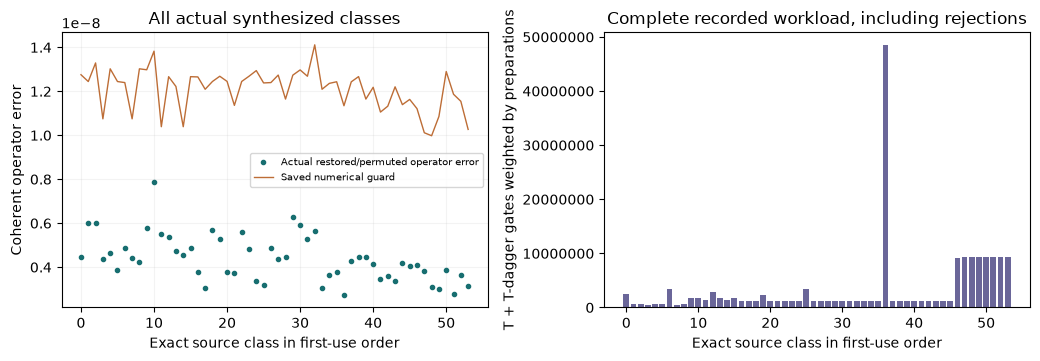

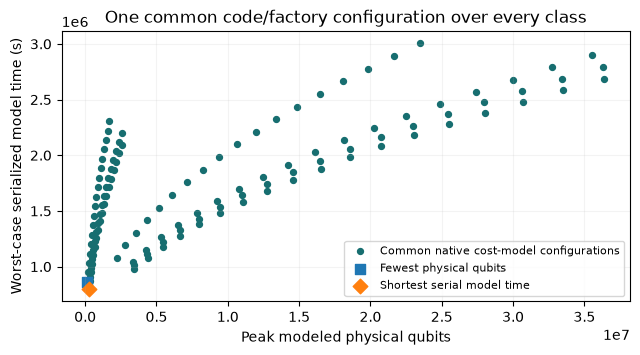

{'archived_CPU_optimizer_seconds': 0.07022566700106836, 'archived_CPU_objective_seconds': 0.06934649698632711, 'archived_CPU_controller_seconds': 0.0008791700147412485, 'new_actual_synthesis_validation_seconds': 5.853648581014568, 'quantum_hardware_optimizer_scoring_latency': None, 'measured_exclusions': 'CPU archive/synthesis/verification timings are measured separately; no hardware optimizer, scoring, decoder or communication latency measured', 'formal_coverage': 'Classical C4 reference coverage only'}


In [10]:
import matplotlib.pyplot as plt
from IPython.display import display

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
x = np.arange(len(numerical_rows))
axes[0].plot(x, [row['actual_error'] for row in numerical_rows], '.', color='#176e70', label='Actual restored/permuted operator error')
axes[0].plot(x, [row['guarded_eta'] for row in numerical_rows], '-', color='#bd6d36', lw=1, label='Saved numerical guard')
axes[0].set(xlabel='Exact source class in first-use order', ylabel='Coherent operator error', title='All actual synthesized classes')
axes[0].legend(fontsize=7); axes[0].grid(alpha=.15)
axes[1].bar(x, [row['shots'] * row['T_or_Tdg'] for row in numerical_rows], color='#6a6699')
axes[1].set(xlabel='Exact source class in first-use order', ylabel='T + T-dagger gates weighted by preparations',
            title='Complete recorded workload, including rejections')
axes[1].ticklabel_format(axis='y', style='plain', useOffset=False)
fig.tight_layout(); display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.scatter([row['peak_physical_qubits'] for row in common],
           [row['worst_case_serial_runtime_ns'] / 1e9 for row in common], color='#176e70', s=18,
           label='Common native cost-model configurations')
for row, marker, label in ((minimum_qubits, 's', 'Fewest physical qubits'), (minimum_runtime, 'D', 'Shortest serial model time')):
    ax.scatter(row['peak_physical_qubits'], row['worst_case_serial_runtime_ns'] / 1e9,
               marker=marker, s=55, label=label)
ax.set(xlabel='Peak modeled physical qubits', ylabel='Worst-case serialized model time (s)',
       title='One common code/factory configuration over every class')
ax.legend(fontsize=8); ax.grid(alpha=.15)
fig.tight_layout(); display(fig); plt.close(fig)
classical = raw_record['classical_work']
assert classical['quantum_hardware_optimizer_scoring_latency'] is None
np.testing.assert_allclose([classical['archived_optimizer_wall_seconds'], classical['archived_objective_wall_seconds'],
                           classical['archived_control_wall_seconds']],
                          [run['optimizer_wall_seconds'], run['objective_wall_seconds'], run['classical_control_seconds']],
                          rtol=0, atol=0)
print({'archived_CPU_optimizer_seconds':classical['archived_optimizer_wall_seconds'],
       'archived_CPU_objective_seconds':classical['archived_objective_wall_seconds'],
       'archived_CPU_controller_seconds':classical['archived_control_wall_seconds'],
       'new_actual_synthesis_validation_seconds':classical['actual_synthesis_validation_wall_seconds'],
       'quantum_hardware_optimizer_scoring_latency':None,
       'measured_exclusions':classical['exclusion'],
       'formal_coverage':'Classical C4 reference coverage only'})


In [11]:
import csv

storage = manifest['physical_storage']
assert storage['encoding'] == 'json-content-dag-v1'
packed_bytes, packed_sha256 = saved_gzip_bytes(storage['file'])
assert packed_sha256 == storage['sha256']
packed = json.loads(packed_bytes)
assert packed['codec'] == 'json-content-dag-v1' and packed['schema_version'] == 1
assert len(packed['nodes']) <= completion_recipe['codec_limits']['max_nodes']
hashes, heights, references, seen_hashes = [], [], 0, set()
for index, (expected, tag, payload) in enumerate(packed['nodes']):
    assert expected not in seen_hashes
    if tag == 'list':
        assert all(type(child) is int and 0 <= child < index for child in payload)
        content, children = [hashes[child] for child in payload], payload
        references += len(payload)
    elif tag == 'dict':
        children = [child for pair in payload for child in pair]
        assert all(type(child) is int and 0 <= child < index for child in children)
        assert all(packed['nodes'][key][1] == 'str' for key, value in payload)
        assert len({key for key, value in payload}) == len(payload)
        content = [[hashes[key], hashes[value]] for key, value in payload]
        references += len(children)
    else:
        assert tag in {'null','bool','int','float','str'}
        if tag == 'null': assert payload is None
        if tag == 'bool': assert type(payload) is bool
        if tag == 'int': assert str(int(payload)) == payload
        if tag == 'float':
            assert math.isfinite(float.fromhex(payload)) and float.fromhex(payload).hex() == payload
        if tag == 'str': assert type(payload) is str
        content, children = payload, []
    material = json.dumps([tag, content], ensure_ascii=True, separators=(',', ':'), allow_nan=False).encode('ascii')
    assert digest_bytes(material) == expected
    hashes.append(expected); seen_hashes.add(expected)
    heights.append(1 + max((heights[child] for child in children), default=-1) if tag in {'list','dict'} else 0)
assert references <= completion_recipe['codec_limits']['max_references']
assert heights[packed['root']] <= completion_recipe['codec_limits']['max_depth']
assert hashes[packed['root']] == packed['logical_sha256']
statistics = manifest['recovery']['codec_statistics']
assert statistics['nodes'] == len(packed['nodes']) and statistics['references'] == references
assert statistics['maximum_depth'] == heights[packed['root']]
assert statistics['encoded_bytes'] == len(packed_bytes) and statistics['logical_sha256'] == packed['logical_sha256']
for name, key in (('resources.json', 'resources'), ('conditional-readout.json', 'conditional_readout'),
                  ('classical-work.json', 'classical_work')):
    value, _ = read_json(name)
    assert value == raw_record[key], name
timing, _ = read_json('completion-timing.json')
assert timing == manifest['timing']['completion']
assert timing['identity'] == identity and timing['status'] == 'complete'
assert timing['wall_cap_seconds'] == completion_recipe['cumulative_physical_wall_cap_seconds'] == 120
np.testing.assert_allclose(timing['first_wall_seconds'] + timing['recovery_wall_seconds'], timing['cumulative_wall_seconds'],
                          rtol=1e-12, atol=1e-9)
assert 0 <= timing['cumulative_wall_seconds'] <= 120
original_physical, _ = read_json('timing/physical.json')
assert original_physical == manifest['timing']['original_physical']
assert original_physical['identity'] == original_identity and original_physical['status'] == 'incomplete'
np.testing.assert_allclose(original_physical['total_wall_seconds'], timing['first_wall_seconds'], rtol=0, atol=1e-12)
synthesis_timing, _ = read_json('timing/synthesis.json')
assert synthesis_timing == manifest['timing']['synthesis']
assert synthesis_timing['identity'] == original_identity and synthesis_timing['status'] == 'complete'
assert 0 <= synthesis_timing['total_wall_seconds'] <= synthesis_timing['wall_cap_seconds'] == 300
np.testing.assert_allclose(sum(row['wall_seconds'] for row in synthesis_timing['invocations']), synthesis_timing['total_wall_seconds'],
                          rtol=1e-12, atol=1e-12)
first = completion_recipe['first_known_query_counts']
second = physical['query_audit']['counts']
cumulative = {key:first[key] + second.get(key, 0) for key in first}
assert first == timing['first_query_counts'] == manifest['recovery']['first_query_counts']
assert second == timing['second_query_counts'] == manifest['recovery']['second_query_counts']
assert cumulative == manifest['recovery']['cumulative_query_counts']
assert all(value <= completion_recipe['cumulative_query_caps'][key] for key, value in cumulative.items())
assert manifest['recovery']['first_complete_result_unavailable'] is True
assert manifest['recovery']['roundtrip_exact_to_second_live_value'] is True
assert manifest['recovery']['quantum_preparations_counted_once'] == 82_032
failure_path = manifest['old_failure_file']
assert digest_bytes(artifact_path(failure_path).read_bytes()) == completion_recipe['original_failure_sha256']
assert digest_bytes(artifact_path('timing/physical.json').read_bytes()) == completion_recipe['first_physical_timing_sha256']
with artifact_path('groups.csv').open(newline='') as handle:
    group_rows = list(csv.DictReader(handle))
assert len(group_rows) == 110 and [int(row['chronological_group_index']) for row in group_rows] == list(range(110))
class_by_id = {row['class_id']:row for row in class_meta}
for saved in group_rows:
    item = class_by_id[saved['class_id']]
    phase, index = saved['phase'], int(saved['evaluation_index'])
    original = batch_by_key[(phase,index)]
    assert json.loads(saved['parameters']) == item['parameters'] == original['parameters']
    assert int(saved['shots']) == original['shots'] and saved['role'] == original['role']
    call = run['evaluations'][index] if phase == 'training' else holdout
    assert saved['accepted'] == str(call.get('accepted',False))
    assert float(saved['objective_estimate']) == call['objective_estimate']
    assert float(saved['standard_error']) == call['estimated_standard_error']
    assert json.loads(saved['counts']) == call['groups'][0]['counts']
    assert json.loads(saved['rng']) == call['groups'][0]['rng']
    for role, column in (('recorded_source','recorded_source_sha256'), ('routed','routed_sha256'), ('clifford_t','clifford_t_sha256')):
        assert saved[column] == item['circuits'][role]['sha256']
with artifact_path('classes.csv').open(newline='') as handle:
    class_rows = list(csv.DictReader(handle))
assert len(class_rows) == 54
for saved, item in zip(class_rows,class_meta):
    assert saved['class_id'] == item['class_id'] and json.loads(saved['parameters']) == item['parameters']
    assert int(saved['shots']) == item['shots'] and int(saved['batches']) == len(item['batches'])
    assert int(saved['actual_t_per_preparation']) == sum(item['actual_synthesis']['clifford_t_counts'].get(name,0) for name in ('t','tdg'))
    assert float(saved['actual_operator_error']) == item['checks']['actual_full_operator_error']
    assert float(saved['guarded_operator_error']) == item['actual_synthesis']['guarded_numerical_operator_error_upper_estimate']
summary, _ = read_json('physical-summary.json')
assert summary['profile'] == physical['profile'] and summary['conditional'] is True and summary['hardware_guarantee'] is False
assert summary['budgets'] == {'physical':.0025,'factory_availability':.0025}
for row, key in zip(summary['selections'], ('selected_minimum_qubits','selected_minimum_runtime')):
    assert all(value == physical[key][name] for name,value in row.items() if name != 'selection')
    macro = raw_record['resources']['physical_macro_totals'][key]
    points = physical[key]['per_physical_class']
    totals = {name:sum(physical_classes[row['physical_class_id']]['shots'] * sum(op['count'] * op[name]
                    for op in row['point']['macro_ledger_per_complete_attempt']) for row in points)
              for name in ('readouts','preparations','decisions')}
    assert all(macro[name] == total for name,total in totals.items())
size, _ = read_json(manifest['artifact_size_file'])
assert size['scope'] == 'all regular files in this generated bundle including this size record'
assert size['parent_archive_copied'] is False and size['private_cache_included'] is False
assert size['frozen_byte_cap'] == recipe['bounds']['artifact_bytes'] == 16 * 1024 * 1024
inventory, standalone_notebook_bytes = {}, 0
for candidate in sorted(artifact_folder.rglob('*')):
    mode = candidate.lstat().st_mode
    assert stat.S_ISREG(mode) or stat.S_ISDIR(mode)
    if stat.S_ISREG(mode):
        if candidate.parent == artifact_folder and candidate.name == 'optimization_compiled.ipynb':
            standalone_notebook_bytes = candidate.stat().st_size
            continue
        inventory[str(candidate.relative_to(artifact_folder))] = candidate.stat().st_size
assert len(inventory) == size['files'] and sum(inventory.values()) == size['total_bytes'] <= size['frozen_byte_cap']
assert not any('__pycache__' in Path(name).parts or name.endswith(('.pyc','.pickle','.pkl')) for name in inventory)
print({'generated_artifact_files':size['files'], 'generated_artifact_bytes':size['total_bytes'],
       'frozen_generated_byte_cap':size['frozen_byte_cap'], 'additional_copied_audit_notebook_bytes':standalone_notebook_bytes,
       'preserved_first_attempt_files':len(original_inventory), 'physical_native_passes':2,
       'cumulative_physical_query_counts':cumulative, 'cumulative_physical_wall_seconds':timing['cumulative_wall_seconds'],
       'quantum_preparations_counted_once':82_032, 'reader_requires_private_pickle':False,
       'first_complete_physical_result_equality_claimed':False, 'audit_started_new_native_or_optimizer_calls':False})


{'generated_artifact_files': 301, 'generated_artifact_bytes': 9614924, 'frozen_generated_byte_cap': 16777216, 'additional_copied_audit_notebook_bytes': 0, 'preserved_first_attempt_files': 281, 'physical_native_passes': 2, 'cumulative_physical_query_counts': {'top_level_calls': 98, 'factory_frontier_queries': 2352, 'factory_frontier_candidates': 24696, 'factory_pipeline_candidates': 816, 'native_trace_queries': 12348}, 'cumulative_physical_wall_seconds': 46.301233375001175, 'quantum_preparations_counted_once': 82032, 'reader_requires_private_pickle': False, 'first_complete_physical_result_equality_claimed': False, 'audit_started_new_native_or_optimizer_calls': False}


Successful execution checks the saved source decisions, actual primitive circuit files, omitted global phases, logical output permutations, complete repetition weights, numerical realization budget and one common conditional physical configuration without generating a new optimization or compilation result. A static compiled replay does not prove that another noisy or synthesized adaptive optimizer would produce this transcript. Preserve every archived target miss and inconclusive VQE label when using these artifacts.
